# Feed-forward optimizer comparison

Forecast 24 hours of ERCOT load with one network architecture and two optimization methods. The train period is 2018?2023, validation is 2024?2025, and the shared forecast hours in 2026 are used for the final comparison. Run the cells in order. Results are saved to `optimization/results/feedforward/`.


## 1. Load and scale the data

Reuse the causal 67 inputs from Step 0. Standardize each of the 24 target hours using training means and standard deviations. Convert predictions back to MW before scoring them.


In [1]:
import copy
import json
import platform
import sys
from pathlib import Path
from time import perf_counter

import matplotlib
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
from torch import nn
from torch.nn.utils import parameters_to_vector, vector_to_parameters

matplotlib.use("Agg")
from matplotlib import pyplot as plt

working_dir = Path.cwd().resolve()
locations = (working_dir, working_dir.parent, working_dir / "final project" / "ERCOT Project")
root = next((path for path in locations if (path / "src" / "data_pipeline.py").is_file()), None)
if root is None:
    raise FileNotFoundError("Start the kernel from optimization/, the ERCOT Project root, or the course workspace.")
sys.path.insert(0, str(root))
from src.config import FEATURES_NPZ_PATH, RAW_CSV_PATH
from src.data_pipeline import build_feature_dict_from_raw

output_dir = root / "optimization" / "results" / "feedforward"
output_dir.mkdir(parents=True, exist_ok=True)
seed, passes, batch_size, cpu_threads = 42, 100, 32, 1
sgd_rates = (0.001, 0.01, 0.03)
initial_step, shrink, sufficient_decrease, max_search = 1.0, 0.5, 1e-4, 50
torch.set_num_threads(cpu_threads)

keys = ("X_scaled", "Y", "splits", "target_dates")
if FEATURES_NPZ_PATH.is_file():
    feature_source = FEATURES_NPZ_PATH
    with np.load(feature_source, allow_pickle=False) as cache:
        features, targets, splits, dates = (cache[key] for key in keys)
else:
    feature_source = RAW_CSV_PATH if RAW_CSV_PATH.is_file() else root.parent / "proposal" / RAW_CSV_PATH.name
    _, _, bundle = build_feature_dict_from_raw(feature_source)
    features, targets, splits, dates = (bundle[key] for key in keys)

if features.shape != (len(splits), 67) or targets.shape != (len(splits), 24):
    raise ValueError("Expected 67 inputs and 24 targets for each forecast day.")
if not np.isfinite(features).all() or not np.isfinite(targets).all():
    raise ValueError("The feature and target arrays must be finite.")
train, val, test = (splits == label for label in ("train", "val", "test"))
if not pd.Index(dates).is_unique or not max(dates[train]) < min(dates[val]) <= max(dates[val]) < min(dates[test]):
    raise ValueError("Expected unique dates and chronologically ordered splits.")
x = torch.from_numpy(features.astype(np.float64))
y_mw = torch.from_numpy(targets.astype(np.float64))
target_mean = y_mw[train].mean(dim=0)
target_sd = y_mw[train].std(dim=0, correction=0)
if not (target_sd > 0).all():
    raise ValueError("Each target hour must vary in the training period.")
y = (y_mw - target_mean) / target_sd

display(pd.DataFrame({"split": ["Train", "Validation", "Test"],
                      "start": [min(dates[m]) for m in (train, val, test)],
                      "end": [max(dates[m]) for m in (train, val, test)],
                      "days": [m.sum() for m in (train, val, test)]}))


,split,start,end,days
0,Train,2018-01-08,2023-12-31,2184
1,Validation,2024-01-01,2025-12-31,731
2,Test,2026-01-01,2026-11-04,306


## 2. Define both optimizer updates

The full-batch update starts with step size 1 and halves it until the Armijo sufficient-decrease condition holds. An accepted step satisfies `f(w ? step*g) ? f(w) ? 0.0001*step*||g||?`. SGD uses one gradient per mini-batch and a fixed learning rate. Both methods minimize standardized mean squared error.


In [2]:
torch.manual_seed(seed)
initial_model = nn.Sequential(nn.Linear(67, 64), nn.ReLU(), nn.Linear(64, 24)).double()
loss_fn = nn.MSELoss()
train_x, train_y = x[train], y[train]
val_x, val_y_mw = x[val], y_mw[val]

def armijo_update(model):
    params = list(model.parameters())
    model.zero_grad(set_to_none=True)
    loss = loss_fn(model(train_x), train_y)
    loss.backward()
    with torch.no_grad():
        start = parameters_to_vector(params)
        grad = parameters_to_vector([p.grad for p in params])
        squared_norm = grad.square().sum().item()
        base_loss = loss.item()
        step = initial_step
        for evaluations in range(1, max_search + 1):
            vector_to_parameters(start - step * grad, params)
            candidate_loss = loss_fn(model(train_x), train_y).item()
            if candidate_loss <= base_loss - sufficient_decrease * step * squared_norm:
                return step, evaluations
            step *= shrink
        vector_to_parameters(start, params)
    raise RuntimeError("Armijo line search exhausted the trial steps.")

def sgd_pass(model, optimizer, generator):
    order = torch.randperm(len(train_x), generator=generator)
    for batch in order.split(batch_size):
        optimizer.zero_grad(set_to_none=True)
        loss_fn(model(train_x[batch]), train_y[batch]).backward()
        optimizer.step()
    return (len(order) + batch_size - 1) // batch_size

@torch.no_grad()
def monitor(model):
    train_loss = loss_fn(model(train_x), train_y).item()
    validation = model(val_x) * target_sd + target_mean
    validation_mae = (validation - val_y_mw).abs().mean().item()
    if not np.isfinite([train_loss, validation_mae]).all():
        raise ValueError("Training produced a non-finite loss or validation error.")
    return {"training_mse": train_loss, "validation_mae_mw": validation_mae}

def train_run(method, learning_rate=None, *, starting_model=initial_model, shuffle_seed=seed):
    model = copy.deepcopy(starting_model)
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate) if learning_rate is not None else None
    generator = torch.Generator().manual_seed(shuffle_seed)
    started = perf_counter()
    steps, gradients, search_evals, optimizer_seconds = [], 0, 0, 0.0
    best_mae, best_pass, best_state = float("inf"), None, None

    for epoch in range(passes + 1):
        step = None
        if epoch:
            update_start = perf_counter()
            if optimizer is None:
                step, evaluations = armijo_update(model)
                gradients += 1
                search_evals += evaluations
            else:
                gradients += sgd_pass(model, optimizer, generator)
            optimizer_seconds += perf_counter() - update_start

        diagnostics = monitor(model)
        steps.append({"method": method, "pass": epoch, "optimizer_seconds": optimizer_seconds,
                      "gradient_evaluations": gradients, "line_search_evaluations": search_evals,
                      "armijo_step": step, **diagnostics})
        if diagnostics["validation_mae_mw"] < best_mae:
            best_mae, best_pass = diagnostics["validation_mae_mw"], epoch
            best_state = copy.deepcopy(model.state_dict())

    duration = perf_counter() - started
    summary = {"method": method, "learning_rate": learning_rate, "best_pass": best_pass,
               "validation_mae_mw": best_mae, "optimizer_seconds": optimizer_seconds,
               "run_seconds": duration, "gradient_evaluations": gradients,
               "line_search_evaluations": search_evals}
    return {"summary": summary, "history": pd.DataFrame(steps), "weights": best_state}


## 3. Train, select on validation, and freeze the checkpoints

Run Armijo and the three planned SGD learning rates for 100 passes from the same weights. One full-batch pass computes one gradient. One SGD pass visits every training example in shuffled batches of 32. Retain each run?s lowest-validation-MAE checkpoint, then select the SGD rate by validation MAE. The SGD table includes the cost of all learning-rate trials.


In [3]:
armijo = train_run("Armijo GD")
sgd_trials = [train_run(f"SGD {rate:g}", rate) for rate in sgd_rates]
chosen_sgd = min(sgd_trials, key=lambda run: run["summary"]["validation_mae_mw"])
selected = (armijo, chosen_sgd)
trials = pd.DataFrame([run["summary"] for run in (armijo, *sgd_trials)])
history = pd.concat([run["history"] for run in (armijo, *sgd_trials)], ignore_index=True)
trials.to_csv(output_dir / "validation_trials.csv", index=False)
history.to_csv(output_dir / "training_history.csv", index=False)

settings = {
    "notebook": "optimization/feedforward_optimizers.ipynb",
    "feature_source": str(feature_source.relative_to(root.parent)),
    "architecture": [67, 64, 24], "activation": "ReLU", "dtype": "float64",
    "seed": seed, "passes": passes, "batch_size": batch_size, "cpu_threads": cpu_threads,
    "armijo": {"initial_step": initial_step, "shrink": shrink,
               "sufficient_decrease": sufficient_decrease, "max_search": max_search},
    "sgd_learning_rates": sgd_rates,
    "sgd_total_selection_seconds": sum(run["summary"]["run_seconds"] for run in sgd_trials),
    "selection": [run["summary"] for run in selected],
    "environment": {"python": platform.python_version(), "processor": platform.processor(),
                    "platform": platform.platform(), "torch": str(torch.__version__),
                    "numpy": np.__version__, "pandas": pd.__version__, "matplotlib": matplotlib.__version__},
}
(output_dir / "settings.json").write_text(json.dumps(settings, indent=2) + "\n", encoding="utf-8")
display(trials)
print(f"Frozen SGD rate {chosen_sgd['summary']['learning_rate']:g}")
print(f"Total SGD selection time {settings['sgd_total_selection_seconds']:.3f} s")


Frozen SGD rate 0.03
Total SGD selection time 8.389 s


,method,learning_rate,best_pass,validation_mae_mw,optimizer_seconds,run_seconds,gradient_evaluations,line_search_evaluations
0,Armijo GD,NaN,100,2033.085059,0.421296,0.564648,100,185
1,SGD 0.001,0.001,100,2801.426184,2.626604,2.820296,6900,0
2,SGD 0.01,0.010,98,1993.054022,2.613278,2.777114,6900,0
3,SGD 0.03,0.030,98,1777.380475,2.614808,2.791606,6900,0


## 4. Score both forecasts on the same 2026 hours

Use the 301 days shared by the preliminary forecasts and verify the target loads before scoring. Both test forecasts use the checkpoints already selected on validation.


In [4]:
preliminary = root / "preliminary"
ml = pd.read_csv(preliminary / "ercot_ml_24hour_forecasts.csv", parse_dates=["timestamp"])
lstm = pd.read_csv(preliminary / "lstm_outputs" / "lstm_day_ahead_forecasts.csv", parse_dates=["timestamp"])
lstm = lstm.loc[lstm["split"] == "test", ["timestamp", "actual_mw"]]
shared = ml[["timestamp", "actual_load_mw"]].merge(lstm, on="timestamp", validate="one_to_one")
shared = shared.sort_values("timestamp")
day_counts = shared.groupby(shared["timestamp"].dt.normalize()).size()
if len(day_counts) != 301 or not day_counts.eq(24).all():
    raise ValueError("Expected the 301 complete shared test days.")
np.testing.assert_array_equal(shared["actual_load_mw"], shared["actual_mw"])
test_index = pd.DatetimeIndex(pd.to_datetime(dates[test])).repeat(24)
test_index += pd.to_timedelta(np.tile(np.arange(24), test.sum()), unit="h")
actual = pd.Series(targets[test].ravel(), index=test_index).reindex(shared["timestamp"]).to_numpy()
np.testing.assert_allclose(actual, shared["actual_mw"], rtol=0, atol=1e-6)

forecasts = shared[["timestamp", "actual_mw"]].copy()
results = []
model = copy.deepcopy(initial_model)
for name, run in zip(("armijo_mw", "sgd_mw"), selected):
    model.load_state_dict(run["weights"])
    with torch.no_grad():
        prediction = (model(x[test]) * target_sd + target_mean).numpy().ravel()
    forecasts[name] = pd.Series(prediction, index=test_index).reindex(shared["timestamp"]).to_numpy()
    errors = (forecasts[name] - forecasts["actual_mw"]).to_numpy()
    if not np.isfinite(errors).all():
        raise ValueError(f"Incomplete predictions for {name}.")
    results.append({
        **run["summary"], "test_days": len(day_counts), "test_hours": len(errors),
        "test_mae_mw": np.abs(errors).mean(), "test_rmse_mw": np.sqrt((errors ** 2).mean()),
    })

comparison = pd.DataFrame(results)
forecasts.to_csv(output_dir / "test_forecasts.csv", index=False)
comparison.to_csv(output_dir / "comparison.csv", index=False)
display(comparison)


,method,learning_rate,best_pass,validation_mae_mw,optimizer_seconds,run_seconds,gradient_evaluations,line_search_evaluations,test_days,test_hours,test_mae_mw,test_rmse_mw
0,Armijo GD,NaN,100,2033.085059,0.421296,0.564648,100,185,301,7224,2083.205480,2934.956538
1,SGD 0.03,0.03,98,1777.380475,2.614808,2.791606,6900,0,301,7224,1786.587914,2625.829647


## 5. Plot training progress

Elapsed time counts optimizer updates and line-search work. The table also reports run time including metric checks and checkpoint selection. Dots mark the checkpoints with lowest validation MAE.


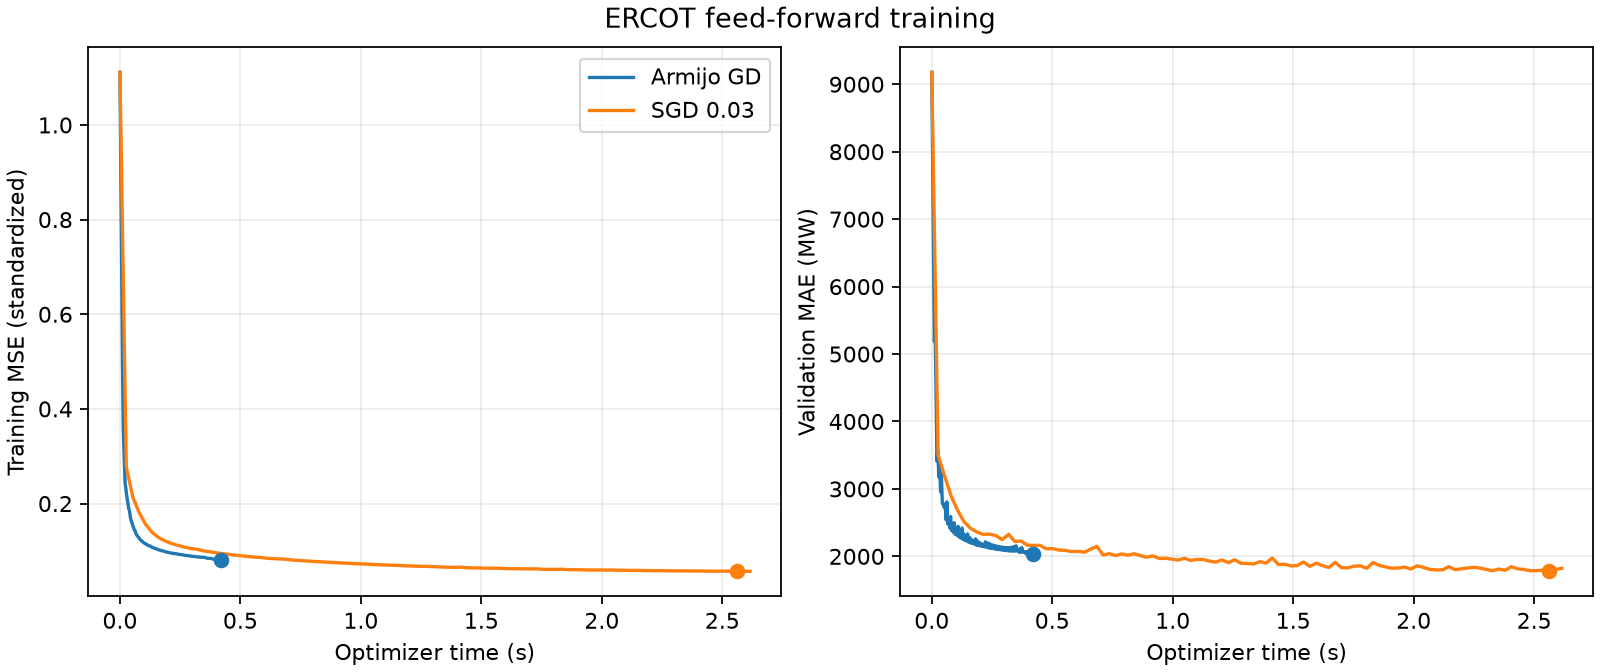

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), layout="constrained")
for run in selected:
    points = run["history"]
    summary = run["summary"]
    checkpoint = points.loc[points["pass"] == summary["best_pass"]].iloc[0]
    for axis, column in zip(axes, ("training_mse", "validation_mae_mw")):
        line, = axis.plot(points["optimizer_seconds"], points[column], label=summary["method"])
        axis.scatter(checkpoint["optimizer_seconds"], checkpoint[column], color=line.get_color(), zorder=3)

for axis, label in zip(axes, ("Training MSE (standardized)", "Validation MAE (MW)")):
    axis.set(xlabel="Optimizer time (s)", ylabel=label)
    axis.grid(alpha=0.25)
axes[0].legend()
fig.suptitle("ERCOT feed-forward training")
plot_path = output_dir / "training_comparison.png"
fig.savefig(plot_path, dpi=160)
plt.close(fig)
display(Image(filename=str(plot_path)))


## 6. Check robustness across initializations

Keep the architecture, data, 100-pass budget, and selected SGD learning rate fixed. Run both methods from identical starting weights at each of seeds 7 and 2026. Include the original seed 42 and compare the best validation MAE from each run.


In [6]:
baseline = pd.read_csv(output_dir / "comparison.csv")
selected_rate = float(baseline["learning_rate"].dropna().item())
seed_records = [
    {"seed": seed, "method": method, "validation_mae_mw": row.validation_mae_mw,
     "best_pass": row.best_pass}
    for method, row in zip(("Armijo GD", "Mini-batch SGD"), baseline.itertuples(index=False), strict=True)
]

for trial_seed in (7, 2026):
    torch.manual_seed(trial_seed)
    starting_model = nn.Sequential(nn.Linear(67, 64), nn.ReLU(), nn.Linear(64, 24)).double()
    for method, rate in (("Armijo GD", None), ("Mini-batch SGD", selected_rate)):
        run = train_run(method, rate, starting_model=starting_model, shuffle_seed=trial_seed)
        result = run["summary"]
        seed_records.append({"seed": trial_seed, "method": method,
                             "validation_mae_mw": result["validation_mae_mw"],
                             "best_pass": result["best_pass"]})

per_seed = pd.DataFrame(seed_records)
paired = per_seed.pivot(index="seed", columns="method", values="validation_mae_mw")
paired["SGD improvement (MW)"] = paired["Armijo GD"] - paired["Mini-batch SGD"]
robustness = per_seed.groupby("method", as_index=False).agg(
    mean_validation_mae_mw=("validation_mae_mw", "mean"),
    sd_validation_mae_mw=("validation_mae_mw", "std"),
)
per_seed.to_csv(output_dir / "robustness_trials.csv", index=False)
robustness.to_csv(output_dir / "robustness_summary.csv", index=False)
display(paired)
display(robustness)


method,Armijo GD,Mini-batch SGD,SGD improvement (MW)
seed,,,
7,2001.985519,1779.643986,222.341533
42,2033.085059,1777.380475,255.704584
2026,2010.436985,1786.339181,224.097805


,method,mean_validation_mae_mw,sd_validation_mae_mw
0,Armijo GD,2015.169188,16.080754
1,Mini-batch SGD,1781.121214,4.658460
